# Single-Frame Detection Debugger

Inspects the background-subtraction segmentation pipeline (`compute_bob_centroid`) for any single video and frame index spotted in `results/plots/{video}_trajectory.png`.

Set `VIDEO_NAME`, `FRAME_INDEX`, and the detection parameters (`THRESHOLD_LOW`, `THRESHOLD_HIGH`, `MORPHOLOGY_DISK_RADIUS`) in the configuration cell below and run all cells.

In [1]:
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage.measure
import skimage.morphology

from labo13.video import load_image_gray, load_video_frame_gray

# === HARDCODED DEBUG PARAMETERS ===
VIDEO_NAME: str = "IMG_1556"
FRAME_INDEX: int = 490  # e.g. outlier frame 360 in IMG_1556, or normal frame 120
THRESHOLD_LOW: float = 20.0
THRESHOLD_HIGH: float = 255.0
MORPHOLOGY_DISK_RADIUS: int = 3
ROI_Y_START: int = 1080
ROI_Y_END: int = 2080
ROI_X_START: int = 0
ROI_X_END: int = 3840


In [2]:
REPO_ROOT: Path = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
FRAMES_DIR: Path = REPO_ROOT / "media" / "frames" / VIDEO_NAME
BG_PATH: Path = REPO_ROOT / "media" / "raw" / "images" / "superfotograma.png"
VIDEO_PATH: Path = REPO_ROOT / "media" / "raw" / "videos" / f"{VIDEO_NAME}.MOV"

matching_pngs: list[Path] = sorted(FRAMES_DIR.glob(f"{VIDEO_NAME}_f{FRAME_INDEX:06d}_t*.png"))
if matching_pngs:
    frame_source: str = f"PNG ({matching_pngs[0].name})"
    frame_gray = load_image_gray(matching_pngs[0])
else:
    frame_source = f"MOV ({VIDEO_PATH.name}, frame {FRAME_INDEX})"
    frame_gray = load_video_frame_gray(VIDEO_PATH, frame_index=FRAME_INDEX)

background_gray = load_image_gray(BG_PATH)

# Cut the frame to the below region of interest (ROI) to avoid the black borders and the timestamp
frame_gray = frame_gray[ROI_Y_START:ROI_Y_END, ROI_X_START:ROI_X_END]
background_gray = background_gray[ROI_Y_START:ROI_Y_END, ROI_X_START:ROI_X_END]

print(f"Loaded {VIDEO_NAME} frame {FRAME_INDEX} from {frame_source} | shape={frame_gray.shape}")
print(f"Loaded background from {BG_PATH.name} | shape={background_gray.shape}")


Loaded IMG_1556 frame 490 from PNG (IMG_1556_f000490_t8.1667.png) | shape=(1000, 3840)
Loaded background from superfotograma.png | shape=(1000, 3840)


In [3]:
diff_image = background_gray.astype(np.float64) - frame_gray.astype(np.float64)
#diff_image = np.abs(diff_image) # Convert to absolute values
raw_mask = (diff_image > THRESHOLD_LOW) & (diff_image < THRESHOLD_HIGH)
closed_mask = skimage.morphology.closing(
    raw_mask, skimage.morphology.disk(MORPHOLOGY_DISK_RADIUS)
)
labels = skimage.measure.label(closed_mask)
regions = sorted(skimage.measure.regionprops(labels), key=lambda r: float(r.area), reverse=True)

if regions:
    x_px = float(round(regions[0].centroid[1]))
    y_px = float(round(regions[0].centroid[0]))
else:
    x_px = float("nan")
    y_px = float("nan")
print(f"Detected centroid: (x={x_px}, y={y_px}) | Candidate regions: {len(regions)}")

region_rows: list[dict[str, float | int]] = [
    {
        "rank": rank,
        "label": int(reg.label),
        "area": int(reg.area),
        "x_centroid": round(float(reg.centroid[1]), 2),
        "y_centroid": round(float(reg.centroid[0]), 2),
        "min_row": int(reg.bbox[0]),
        "min_col": int(reg.bbox[1]),
        "max_row": int(reg.bbox[2]),
        "max_col": int(reg.bbox[3]),
        "eccentricity": round(float(reg.eccentricity), 4),
        "solidity": round(float(reg.solidity), 4),
    }
    for rank, reg in enumerate(regions[:15], start=1)
]
df_regions = pd.DataFrame(region_rows)
df_regions


Detected centroid: (x=2141.0, y=961.0) | Candidate regions: 253


,rank,label,area,x_centroid,y_centroid,min_row,min_col,max_row,max_col,eccentricity,solidity
0,1,208,930,2140.63,961.19,948,2116,976,2168,0.8853,0.8509
1,2,210,22,2094.36,956.59,954,2091,961,2098,0.9098,0.6875
2,3,157,20,2060.10,647.85,643,2057,652,2064,0.6604,0.5000
3,4,125,16,2085.62,524.19,520,2084,530,2088,0.9317,0.6154
4,5,251,15,48.27,998.27,997,44,1000,52,0.9578,0.8824
5,6,131,13,2086.92,541.38,538,2085,545,2089,0.8744,0.6842
6,7,219,9,2095.00,965.00,963,2093,968,2098,0.9338,0.8182
7,8,238,9,91.67,982.11,981,89,984,96,0.9831,0.6923
8,9,67,8,2078.00,298.12,297,2076,300,2081,0.9175,0.7273
9,10,112,8,2087.88,478.88,478,2086,481,2091,0.8449,0.6154


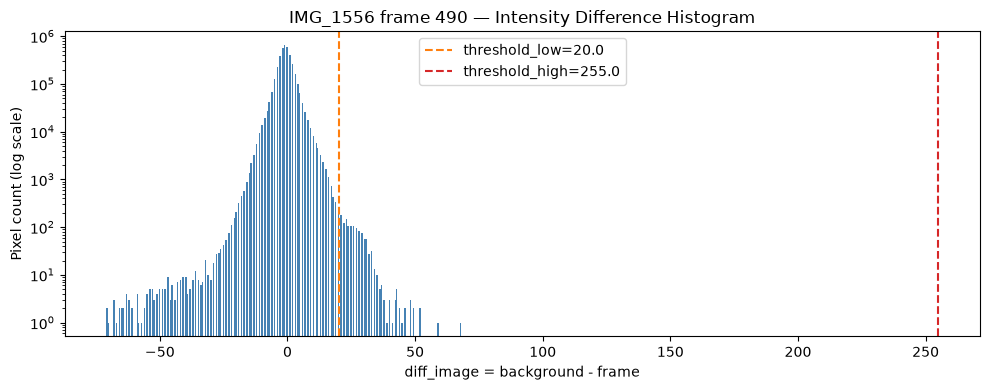

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(diff_image.ravel(), bins=256, color="steelblue")
ax.axvline(THRESHOLD_LOW, color="C1", linestyle="--", linewidth=1.5, label=f"threshold_low={THRESHOLD_LOW}")
ax.axvline(THRESHOLD_HIGH, color="C3", linestyle="--", linewidth=1.5, label=f"threshold_high={THRESHOLD_HIGH}")
ax.set_yscale("log")
ax.set_xlabel("diff_image = background - frame")
ax.set_ylabel("Pixel count (log scale)")
ax.set_title(f"{VIDEO_NAME} frame {FRAME_INDEX} — Intensity Difference Histogram")
ax.legend()
plt.tight_layout()
plt.show()


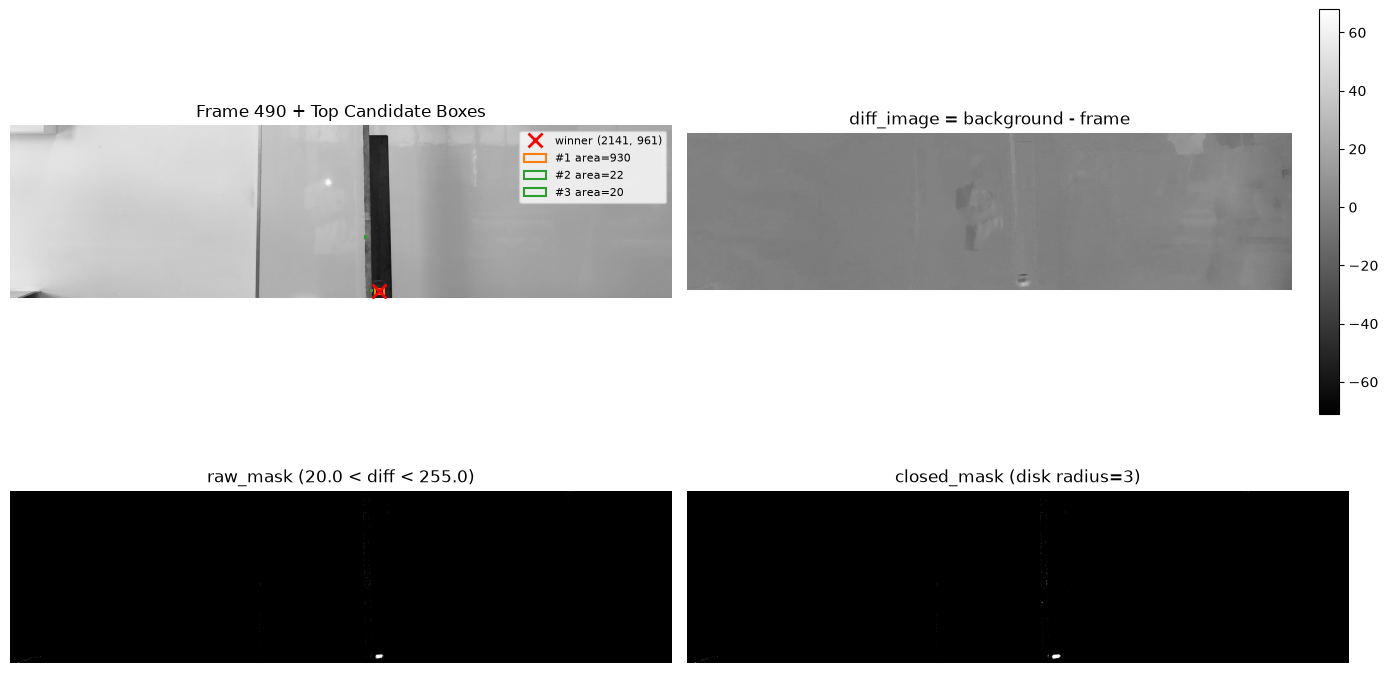

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
(ax_frame, ax_diff), (ax_raw, ax_closed) = axes

ax_frame.imshow(frame_gray, cmap="gray")
if not np.isnan(x_px) and not np.isnan(y_px):
    ax_frame.plot(x_px, y_px, "rx", markersize=10, markeredgewidth=2, label=f"winner ({x_px:.0f}, {y_px:.0f})")
for rank, reg in enumerate(regions[:3], start=1):
    min_r, min_c, max_r, max_c = reg.bbox
    rect = patches.Rectangle(
        (min_c, min_r),
        max_c - min_c,
        max_r - min_r,
        linewidth=1.5,
        edgecolor="C1" if rank == 1 else "C2",
        facecolor="none",
        label=f"#{rank} area={int(reg.area)}",
    )
    ax_frame.add_patch(rect)
ax_frame.set_title(f"Frame {FRAME_INDEX} + Top Candidate Boxes")
ax_frame.legend(loc="upper right", fontsize=8)
ax_frame.axis("off")

im_diff = ax_diff.imshow(diff_image, cmap="gray")
fig.colorbar(im_diff, ax=ax_diff, fraction=0.046, pad=0.04)
ax_diff.set_title("diff_image = background - frame")
ax_diff.axis("off")

ax_raw.imshow(raw_mask, cmap="gray")
ax_raw.set_title(f"raw_mask ({THRESHOLD_LOW} < diff < {THRESHOLD_HIGH})")
ax_raw.axis("off")

ax_closed.imshow(closed_mask, cmap="gray")
ax_closed.set_title(f"closed_mask (disk radius={MORPHOLOGY_DISK_RADIUS})")
ax_closed.axis("off")

plt.tight_layout()
plt.show()


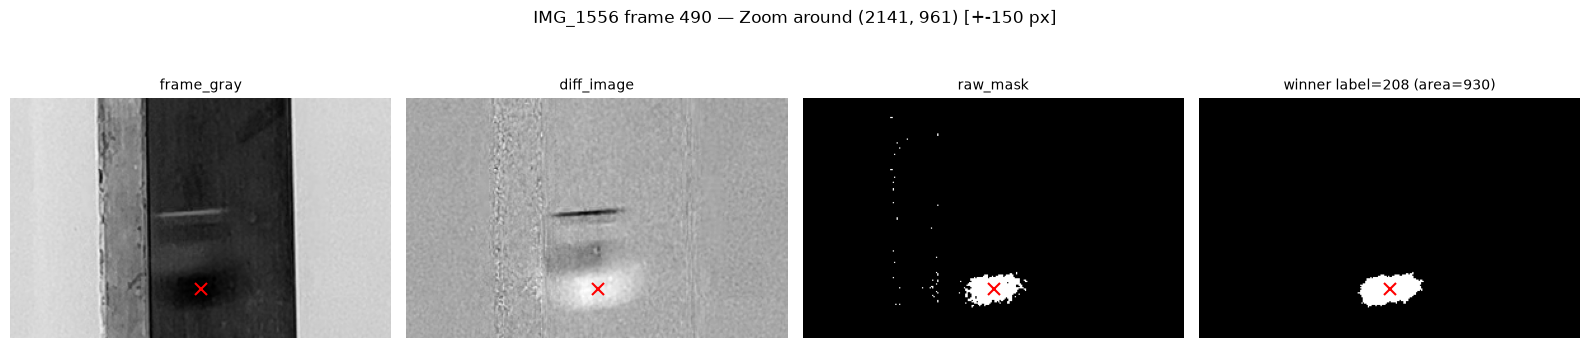

In [6]:
if regions:
    winning_reg = regions[0]
    cx: int = int(round(float(winning_reg.centroid[1])))
    cy: int = int(round(float(winning_reg.centroid[0])))
    half_crop: int = 150
    h_img, w_img = frame_gray.shape
    x0: int = max(0, cx - half_crop)
    x1: int = min(w_img, cx + half_crop)
    y0: int = max(0, cy - half_crop)
    y1: int = min(h_img, cy + half_crop)

    isolated_mask = labels[y0:y1, x0:x1] == winning_reg.label
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    panels = [
        (frame_gray[y0:y1, x0:x1], "frame_gray"),
        (diff_image[y0:y1, x0:x1], "diff_image"),
        (raw_mask[y0:y1, x0:x1], "raw_mask"),
        (isolated_mask, f"winner label={winning_reg.label} (area={int(winning_reg.area)})"),
    ]
    for ax, (patch_img, title) in zip(axes, panels, strict=True):
        ax.imshow(patch_img, cmap="gray")
        ax.plot(cx - x0, cy - y0, "rx", markersize=8, markeredgewidth=1.5)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{VIDEO_NAME} frame {FRAME_INDEX} — Zoom around ({cx}, {cy}) [+-{half_crop} px]")
    plt.tight_layout()
    plt.show()
else:
    print("No connected components found for current thresholds.")
